# Import libraries and configure device

In [1]:
import os 
import random
import numpy as np 
import matplotlib.pyplot as plt 

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader,random_split
from torchvision import datasets,transforms
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF 

# Reproducability 

SEED = 42 

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce GTX 1650


# Load Oxford-IIIT Pet Dataset

In [2]:
IMAGE_SIZE = (256,256)

DATA_DIR = './data'

# Image Transformation 
image_transform = transforms.Compose([
    transforms.Resize(
        IMAGE_SIZE,
        interpolation= InterpolationMode.BILINEAR
    ),
    transforms.ToTensor()
])

# Mask Transformation 

def mask_transform(mask):

    mask = TF.resize(
        mask,
        IMAGE_SIZE,
        interpolation = InterpolationMode.NEAREST
    )

    mask = TF.pil_to_tensor(mask)

    # Pet & Boundary = 1  
    # Background = 0 

    mask = ((mask == 1) | (mask == 3)).float()

    return mask 

# Training and validation source dataset

full_train_dataset = datasets.OxfordIIITPet(
    root = DATA_DIR,
    split= 'trainval',
    target_types= 'segmentation',
    transform= image_transform,
    target_transform= mask_transform,
    download= False
)

# Test Dataset 

test_dataset = datasets.OxfordIIITPet(
    root= DATA_DIR,
    split='test',
    target_types='segmentation',
    transform = image_transform,
    target_transform= mask_transform,
    download= False
)

print("Trainval samples:", len(full_train_dataset))
print("Test samples:", len(test_dataset))

Trainval samples: 3680
Test samples: 3669


# Train / Validation Split and DataLoaders

In [3]:
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size,val_size],
    generator= torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 8 

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 2944
Validation samples: 736
Testing samples: 3669


# Visualize dataset samples

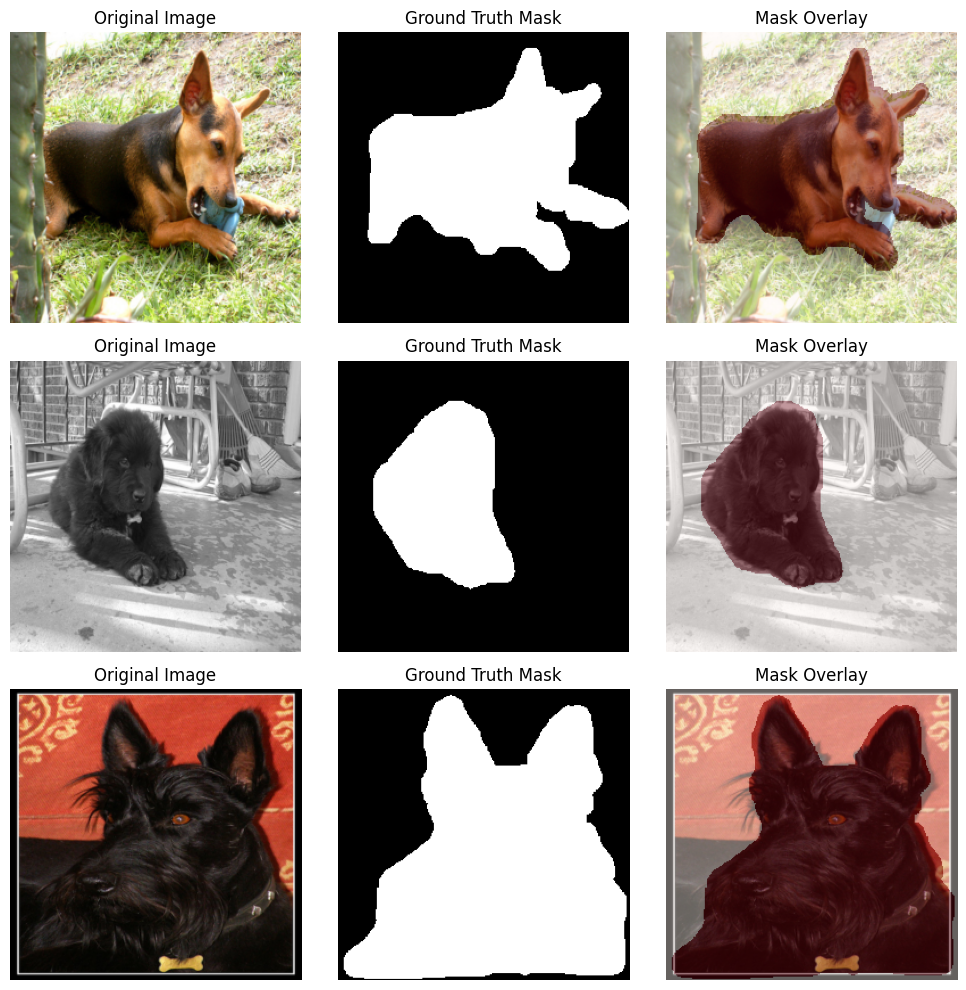

In [4]:
images, masks = next(iter(train_loader))

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for i in range(3):

    axes[i, 0].imshow(images[i].permute(1, 2, 0))
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask")

    overlay = images[i].permute(1, 2, 0).clone()

    axes[i, 2].imshow(overlay)
    axes[i, 2].imshow(
        masks[i, 0],
        cmap="Reds",
        alpha=0.4
    )
    axes[i, 2].set_title("Mask Overlay")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

# Build U-Net from scratch

In [5]:
class ConvBlock(nn.Module):

    def __init__(self,in_channels,out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace= True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace= True)
        )

    def forward(self,x):
        return self.block(x) 

class UNet(nn.Module):

    def __init__(self,in_channels=3,out_channels=1):

        super().__init__()

        self.pool = nn.MaxPool2d(kernel_size=2)

        # Encoder 
        self.enc1 = ConvBlock(in_channels,32)
        self.enc2 = ConvBlock(32,64)
        self.enc3 = ConvBlock(64,128)
        self.enc4 = ConvBlock(128,256)

        # BottleNeck 
        self.bottleneck = ConvBlock(256,512)

        # Decoder 
        self.up4 = nn.ConvTranspose2d(512,256,2,stride=2)
        self.dec4 = ConvBlock(512,256)

        self.up3 = nn.ConvTranspose2d(256,128,2,stride=2)
        self.dec3 = ConvBlock(256,128)

        self.up2 = nn.ConvTranspose2d(128,64,2,stride=2)
        self.dec2 = ConvBlock(128,64)

        self.up1 = nn.ConvTranspose2d(64,32,2,stride=2)
        self.dec1 = ConvBlock(64,32)

        # Final Segmentation Layer 
        self.out = nn.Conv2d(
            32,
            out_channels,
            kernel_size=1
        )

    def forward(self,x):

        # Encoder 
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder + Skip connections
        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.out(d1)


# Initialize model from scratch
model = UNet().to(device)

print(model)

# Parameter count
total_params = sum(p.numel() for p in model.parameters())

print(f"\nTotal parameters: {total_params:,}")

# Test forward pass
sample = torch.randn(2, 3, 256, 256).to(device)

with torch.no_grad():
    output = model(sample)

print("Input shape:", sample.shape)
print("Output shape:", output.shape)


UNet(
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc

# Define loss, optimizer and training functions

In [6]:
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr = 0.001
)

EPOCHS = 10 

def run_epoch(loader, training = False):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0 

    total_intersection = 0 
    total_prediction = 0
    total_target = 0 

    for images,masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        if training:
            optimizer.zero_grad(set_to_none= True)

        with torch.set_grad_enabled(training):

            outputs = model(images)
            loss = criterion(outputs,masks)

        if training:
            loss.backward()
            optimizer.step()

        predictions = (torch.sigmoid(outputs) > 0.5).float()
    
        total_loss += loss.item() * images.size(0)
    
        total_intersection += (predictions * masks).sum().item() #element wise multiplication
    
        total_prediction += predictions.sum().item()
    
        total_target += masks.sum().item()

    avg_loss = total_loss / len(loader.dataset)

    dice = (2 * total_intersection + 1e-7) / (total_prediction + total_target + 1e-7)

    iou = (total_intersection + 1e-7) / (total_prediction + total_target - total_intersection + 1e-7)

    return avg_loss,dice,iou    

# Train the U-Net

In [7]:
# history = {
#     "train_loss": [],
#     "val_loss": [],
#     "train_dice": [],
#     "val_dice": [],
#     "train_iou": [],
#     "val_iou": []
# }

# best_val_dice = -1

# MODEL_PATH = "unet_oxford_pet.pth"

# for epoch in range(EPOCHS):

#     train_loss, train_dice, train_iou = run_epoch(
#         train_loader,
#         training=True
#     )

#     val_loss, val_dice, val_iou = run_epoch(
#         val_loader,
#         training=False
#     )

#     history["train_loss"].append(train_loss)
#     history["val_loss"].append(val_loss)

#     history["train_dice"].append(train_dice)
#     history["val_dice"].append(val_dice)

#     history["train_iou"].append(train_iou)
#     history["val_iou"].append(val_iou)

#     if val_dice > best_val_dice:

#         best_val_dice = val_dice

#         torch.save(
#             model.state_dict(),
#             MODEL_PATH
#         )

#     print(
#         f"Epoch [{epoch+1}/{EPOCHS}] "
#         f"| Train Loss: {train_loss:.4f} "
#         f"| Val Loss: {val_loss:.4f} "
#         f"| Train Dice: {train_dice:.4f} "
#         f"| Val Dice: {val_dice:.4f} "
#         f"| Val IoU: {val_iou:.4f}"
#     )

# print("\nTraining completed!")
# print("Best Validation Dice:", round(best_val_dice, 4))
# print("Best model saved:", MODEL_PATH)

# Plot training performance

In [8]:
# fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# axes[0].plot(history["train_loss"], label="Train")
# axes[0].plot(history["val_loss"], label="Validation")
# axes[0].set_title("Loss")
# axes[0].legend()

# axes[1].plot(history["train_dice"], label="Train")
# axes[1].plot(history["val_dice"], label="Validation")
# axes[1].set_title("Dice Score")
# axes[1].legend()

# axes[2].plot(history["train_iou"], label="Train")
# axes[2].plot(history["val_iou"], label="Validation")
# axes[2].set_title("IoU")
# axes[2].legend()

# for ax in axes:
#     ax.set_xlabel("Epoch")
#     ax.grid(True)

# plt.tight_layout()
# plt.show()

# Evaluate on the test dataset

In [10]:
# Load best checkpoint
MODEL_PATH = "unet_oxford_pet.pth"

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

# Restore best weights
model.load_state_dict(checkpoint)

# Ensure model is on GPU
model = model.to(device)

# Evaluate
test_loss, test_dice, test_iou = run_epoch(
    test_loader,
    training=False
)

print("========== TEST RESULTS ==========")
print(f"Test Loss : {test_loss:.4f}")
print(f"Test Dice : {test_dice:.4f}")
print(f"Test IoU  : {test_iou:.4f}")

========== TEST RESULTS ==========
Test Loss : 0.2751
Test Dice : 0.8590
Test IoU  : 0.7528


# Visualize predictions

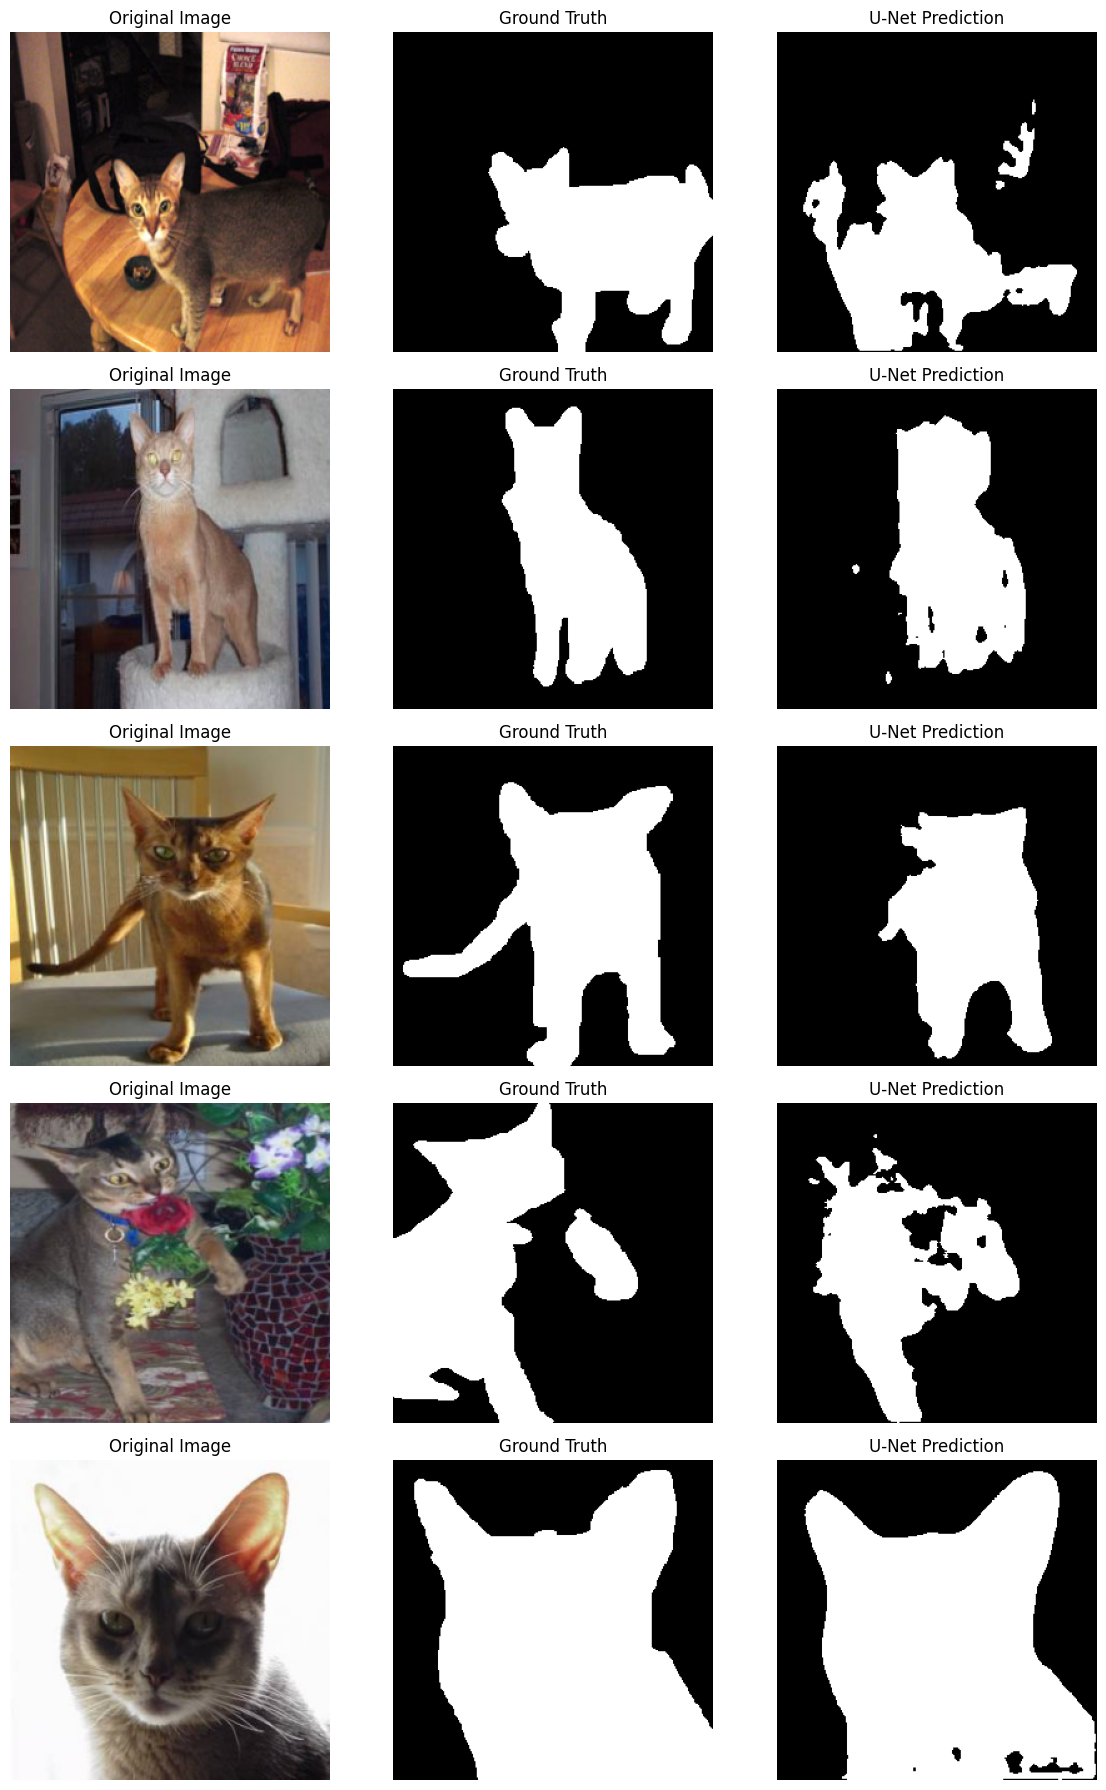

In [11]:
model.eval()

images, masks = next(iter(test_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():

    outputs = model(images)

    predictions = (
        torch.sigmoid(outputs) > 0.5
    ).float()


fig, axes = plt.subplots(5, 3, figsize=(12, 18))

for i in range(5):

    original = images[i].cpu().permute(1, 2, 0)

    ground_truth = masks[i, 0].cpu()

    predicted = predictions[i, 0].cpu()

    axes[i, 0].imshow(original)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(ground_truth, cmap="gray")
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(predicted, cmap="gray")
    axes[i, 2].set_title("U-Net Prediction")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()